# Plot trajectories of multiple icebergs

In [1]:
cd ~/work/tutorials/sources/OpenDrift/openberg_july2026/results

/home/jovyan/work/tutorials/sources/OpenDrift/openberg_july2026/results


In [2]:
# import pandas as pd
# import xarray as xr
# import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import glob
from src.utils import *
from openberg_july2026.src2.utils0 import *
from openberg_july2026.src2.utils2 import *
from openberg_july2026.src2.utils3 import *

In [58]:
# ib_l = ['iceberg2011w1','iceberg2011w2','iceberg2021w','iceberg2025w']
ib_l = ['iceberg2017b','iceberg2018b','iceberg2025w']
ib_period = dict.fromkeys(ib_l,None)
ib_period['iceberg2025w'] = 3
ib_period

{'iceberg2017b': None, 'iceberg2018b': None, 'iceberg2025w': 3}

In [59]:
#read sim
file_d={}
for ib in ib_l:
    file_contain_all = [ib,'gebco']
    file_contain_any = ['_']
    file_notcontain = ['prof','vocean','next',]#'test','wa','next','glorys']#['topaz4','glorys','slope','era5','almost','stokes',]
    file_l = glob.glob("./%s/*.nc"%ib)
    file_l = [f for f in file_l if all(ff in f for ff in file_contain_all)] #filtering for required keywords
    file_l = [f for f in file_l if any(ff in f for ff in file_contain_any)] #filtering for required keywords
    file_l = [f for f in file_l if all(ff not in f for ff in file_notcontain)] #filtering for neglected keywords
    file_d[ib] = file_l
file_d

{'iceberg2017b': ['./iceberg2017b/iceberg2017b_gebco_glorys_windglophyre_joined.nc',
  './iceberg2017b/iceberg2017b_gebco_topaz4_windglophyre.nc',
  './iceberg2017b/iceberg2017b_gebco_topaz4_windglophyre_idx0-0_testcsi2.nc',
  './iceberg2017b/iceberg2017b_gebco_topaz4_windglophyre_idx3-3_testcsi2.nc',
  './iceberg2017b/iceberg2017b_gebco_topaz4_windglophyre_idx1-1_testcsi2.nc',
  './iceberg2017b/iceberg2017b_gebco_topaz4_windglophyre_idx2-2_testcsi2.nc',
  './iceberg2017b/iceberg2017b_gebco_topaz4_windglophyre_idx4-4_testcsi2.nc',
  './iceberg2017b/iceberg2017b_gebco_topaz4_windglophyre_idx5-5_testcsi2.nc',
  './iceberg2017b/iceberg2017b_gebco_topaz4_windglophyre_idx6-6_testcsi2.nc',
  './iceberg2017b/iceberg2017b_gebco_topaz4_windglophyre_idx7-7_testcsi2.nc'],
 'iceberg2018b': ['./iceberg2018b/iceberg2018b_gebco_topaz4_windglophyre.nc',
  './iceberg2018b/iceberg2018b_gebco_glorys_windglophyre_joined.nc',
  './iceberg2018b/iceberg2018b_gebco_topaz6_topaz4_windglophyre_joined.nc'],
 'ic

In [60]:
#dicts and definitions
nono = ('ICEBERG','NEXTSIM','WINDGLOPHYRE','WINDGLOPHYNRT')
legenddict_full = {k:v for k,v in legenddict_full.items() if k not in nono}
legenddict_full = {'NEXTSIMRE':{'col':'plum','alpha':1,'zo':40},**legenddict_full}
legenddict = dict.fromkeys([f.split('/')[-1][:-3] for file_l_ib in file_d.values() for f in file_l_ib])

for f in legenddict:
    ll = []
    for l in legenddict_full:
        # print(f,l,ll)
        if l.lower() in f.lower(): ll = ll+[l]
    if 'TOPAZ5-Ensemble' in ll:
        ll = [lll for lll in ll if lll!='TOPAZ5'] #filter out tp5 if tp5-ens
    # print(ll)
    legenddict[f]={'col':legenddict_full[ll[-1]]['col'], 'alpha':legenddict_full[ll[-1]]['alpha'], 
                   'kw':', '.join(ll).replace('TOPAZ5-Ensemble','TOPAZ5-ENS'),
                   'zo':legenddict_full[ll[-1]]['zo'],
                  }

legenddict 

{'iceberg2017b_gebco_glorys_windglophyre_joined': {'col': 'darkolivegreen',
  'alpha': 1,
  'kw': 'GLORYS',
  'zo': 20},
 'iceberg2017b_gebco_topaz4_windglophyre': {'col': 'darkslateblue',
  'alpha': 1,
  'kw': 'TOPAZ4',
  'zo': 22},
 'iceberg2017b_gebco_topaz4_windglophyre_idx0-0_testcsi2': {'col': 'darkslateblue',
  'alpha': 1,
  'kw': 'TOPAZ4',
  'zo': 22},
 'iceberg2017b_gebco_topaz4_windglophyre_idx3-3_testcsi2': {'col': 'darkslateblue',
  'alpha': 1,
  'kw': 'TOPAZ4',
  'zo': 22},
 'iceberg2017b_gebco_topaz4_windglophyre_idx1-1_testcsi2': {'col': 'darkslateblue',
  'alpha': 1,
  'kw': 'TOPAZ4',
  'zo': 22},
 'iceberg2017b_gebco_topaz4_windglophyre_idx2-2_testcsi2': {'col': 'darkslateblue',
  'alpha': 1,
  'kw': 'TOPAZ4',
  'zo': 22},
 'iceberg2017b_gebco_topaz4_windglophyre_idx4-4_testcsi2': {'col': 'darkslateblue',
  'alpha': 1,
  'kw': 'TOPAZ4',
  'zo': 22},
 'iceberg2017b_gebco_topaz4_windglophyre_idx5-5_testcsi2': {'col': 'darkslateblue',
  'alpha': 1,
  'kw': 'TOPAZ4',
  'zo

In [61]:
# read obs
fname = 'merged_obs10'#'merged_obs_iceberg2026e_1D'
with xr.open_dataset('../input/%s.nc'%fname) as ds:
    ds=ds


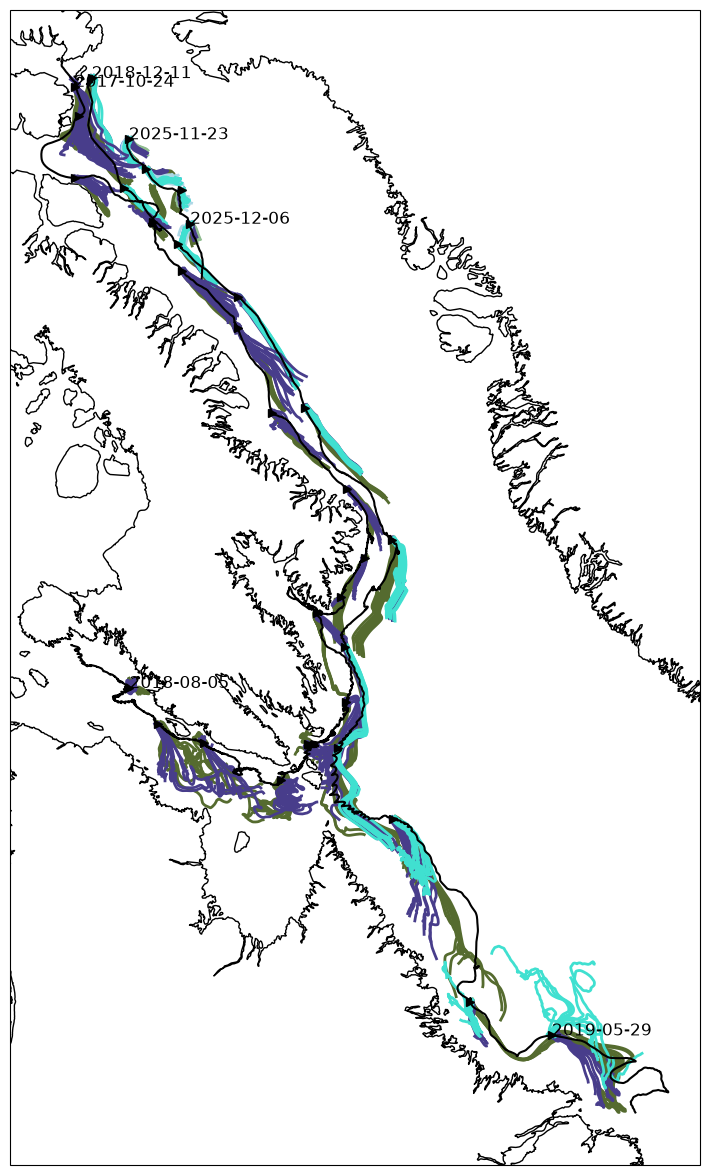

In [62]:
#Map

try: del apn_obs
except: pass


#Figure
fig,ax = plt.subplots(1,1,figsize=(15,15),subplot_kw={'projection':ccrs.NorthPolarStereo(central_longitude=float(obs.lon.mean()))})#central_longitude=20})
ax.coastlines(resolution='10m')
trans = ccrs.PlateCarree()

for ib in ib_l:
    #period
    an = ib_period[ib]
    apn = None if an==None else {'time':dict_analysis_period[ib][an]}

    #obs read
    try:
        obs = ds.sel(iceberg=ib,trajectory_id=ib) 
        obs_seed = obs.isel(time=(obs.seed_idx==1))
    except:
        obs = xr.open_dataset('../input/iceberg-2026.nc')
        obs_seed = obs.sel(time=['2026-07-02','2026-07-26'],method='nearest')
    # plot obs
    zo1=300
    apn_obs=apn
    if apn_obs!=None: obs,obs_seed = obs.sel(apn_obs),obs_seed.sel(apn_obs)
    ax.plot(obs_seed['lon'],obs_seed['lat'],'>',transform=trans,color='k',label='Individual observations',zorder=zo1)#label='Seeding points'
    ax.plot(obs['lon'],obs['lat'],transform=trans,color='k',label='Observed trajectory',zorder=zo1)#Observation
    # for d in range(obs_3day['time'].size):
    for d in (0,-1):#np.arange(obs_seed['time'].sel(apn_obs).size)[::5]:
    #     if d not in [1,2,3,4,5,12,15,16,17,18,19]:
            ax.text(obs_seed['lon'].sel(apn_obs)[d],obs_seed['lat'].sel(apn_obs)[d],
                    obs_seed['time'].sel(apn_obs)[d].values.astype('datetime64[D]').astype(str),transform=trans,color='k',fontsize=12,zorder=zo1)


    # plot sim
    zo2=10
    for inputdataidx, inputdata in enumerate(file_d[ib]):
        sim = xr.open_dataset(inputdata)
        inputdata = inputdata.split('/')[-1][:-3]
        if apn!=None: sim = sim.sel(apn)
        if ib in dict_traj: 
            if inputdata in dict_traj[ib]: sim = sim.sel(trajectory=dict_traj[ib][inputdata])
        # if 'debris' not in inputdata:
        #     ax.plot(sim.lon.sel(trajectory=0).dropna(dim="time")[0],sim.lat.sel(trajectory=0).dropna(dim="time")[0],
        #             '>',linewidth=3,transform=trans,markeredgecolor='k',markerfacecolor=legenddict[inputdata]['col'],zorder=300,
        #            label='Seeding points')
        for traj in sim.trajectory:
            ax.plot(sim.lon.sel(trajectory=traj).dropna(dim="time"),sim.lat.sel(trajectory=traj).dropna(dim="time"),
                    color=legenddict[inputdata]['col'] if 'debris' not in inputdata else 'grey',# if 'idx' not in inputdata else 'red',
                    # label='Simulation w. '+(legenddict[inputdata]['kw'] if 'debris' not in inputdata else 'debris') if traj==0 else '',#if traj==sim.trajectory[0] else '',#) if 'mainrun' not in inputdata else '',
                    label=('Simulation iceberg' if 'debris' not in inputdata else 'Simulation debris') if traj==0 else '',#if traj==sim.trajectory[0] else '',#) if 'mainrun' not in inputdata else '',
                    zorder=legenddict[inputdata]['zo'] if 'idx' not in inputdata else 200,
                    alpha=legenddict[inputdata]['alpha'],
                    linestyle='-' if 'debris' not in inputdata else '-',#) if 'debris' not in inputdata else ':',
                    linewidth=2 if 'debris' not in inputdata else 1,
                    transform=trans)



# #legend
# h, l = ax.get_legend_handles_labels()
# by_label = dict(zip(l, h))
# ax.legend(handles=list(by_label.values()),
#          labels=list(by_label.keys()),
#           loc='best')
         
# # plt.legend()
# subp,pp='',''
# ax.set_title(subp+ib+pp,fontsize=14,weight='bold')
# plt.axis('off')
# note = 'ib+debris_event12'
# # fig.savefig('./results/map_%s%s.png'%(ib,'_'+note if len(note)>0 else ''),dpi=200,transparent=True,bbox_inches='tight')
# plt.show()

